In [ ]:
import tensorflow as tf
from keras.layers import Dense
from keras.models import Sequential
from keras.regularizers import L2
from keras.callbacks import EarlyStopping

In [ ]:
from sklearn import datasets
import torch.nn as nn
import matplotlib.pyplot as plt
x_num,y_num=datasets.make_regression(n_samples=100,n_features=1,noise=30,random_state=1)
x=torch.from_numpy(x_num.astype(np.float32))
y=torch.from_numpy(y_num.astype(np.float32))
y=y.view(y.shape[0],1)
n_samples,n_features=x.shape
input_size=n_features
output_size=1
model=nn.Linear(input_size,output_size)
criterian=nn.MSELoss()
ler=1
optimizer=torch.optim.SGD(model.parameters(),lr=ler)
for i in range(100):
  y_pred=model(x)
  loass=criterian(y_pred,y)
  loass.backward()
  #udate the weight
  optimizer.step()
  optimizer.zero_grad()
  print(f'{loass.item()}:{i}')








6196.67578125:0
2925.53271484375:1
2001.11279296875:2
1769.209228515625:3
1743.545166015625:4
1781.299560546875:5
1840.65478515625:6
1909.50732421875:7
1984.50244140625:8
2064.87158203125:9
2150.62255859375:10
2242.0048828125:11
2339.355224609375:12
2443.05419921875:13
2553.51318359375:14
2671.172119140625:15
2796.49853515625:16
2929.99365234375:17
3072.18994140625:18
3223.65283203125:19
3384.98876953125:20
3556.840087890625:21
3739.8916015625:22
3934.873779296875:23
4142.56396484375:24
4363.791015625:25
4599.4365234375:26
4850.44189453125:27
5117.80517578125:28
5402.59375:29
5705.94384765625:30
6029.06640625:31
6373.24755859375:32
6739.8623046875:33
7130.37255859375:34
7546.33203125:35
7989.404296875:36
8461.3564453125:37
8964.06640625:38
9499.5439453125:39
10069.916015625:40
10677.462890625:41
11324.611328125:42
12013.9375:43
12748.1875:44
13530.2958984375:45
14363.3759765625:46
15250.755859375:47
16195.9736328125:48
17202.798828125:49
18275.23828125:50
19417.578125:51
20634.3671875:

In [ ]:
import pandas as pd


pdi = pd.read_csv(r"/content/kochi_induction_dataset.csv")


pdi['FinalDecision'] = pdi['FinalDecision'].map({"Service": 1, "Standby": 0})

# Boolean to int
bool_cols = ['Rolling_Valid', 'Signalling_Valid', 'Telecom_Valid', 'Any_Fitness_Invalid', 'Critical_JobCard']
for col in bool_cols:
    pdi[col] = pdi[col].astype(int)

# Encode Mileage_Label
pdi['Mileage_Label'] = pdi['Mileage_Label'].map({"Underused": 0, "Overused": 1})
# Fill missing with "NotScheduled"
pdi['Cleaning_Slot_Scheduled'] = pdi['Cleaning_Slot_Scheduled'].fillna("NotScheduled")

def mileage_category(x):
    if x < 120000:
        return "Low"
    elif x < 200000:
        return "Medium"
    else:
        return "High"

pdi["Mileage_Category"] = pdi["cum_mileage"].apply(mileage_category)

# Encode to numeric
pdi["Mileage_Category"] = pdi["Mileage_Category"].map({"Low":0, "Medium":1, "High":2})

# Encode Cleaning_Slot_Scheduled
pdi['Cleaning_Slot_Scheduled'] = pdi['Cleaning_Slot_Scheduled'].map({"NotScheduled": 0, "Scheduled": 1})

# Encode Stabling_Difficulty
pdi['Stabling_Difficulty'] = pdi['Stabling_Difficulty'].map({"Low": 0, "Medium": 1, "High": 2})

# Drop high-textual columns not useful for ML (optional)
pdi = pdi.drop(columns=['Date','Trainset','DecisionReason','Fina'])

# Now ready for ML
print(pdi.head())



    Depot  FinalDecision  Rolling_Valid  Signalling_Valid  Telecom_Valid  \
0  DepotB            1.0              1                 1              1   
1  DepotA            1.0              1                 1              1   
2  DepotA            1.0              1                 1              1   
3  DepotA            1.0              1                 1              1   
4  DepotA            0.0              1                 1              1   

   Any_Fitness_Invalid  Open_JobCards  Critical_JobCard  Branding_Hours_Left  \
0                    0              0                 0                    0   
1                    0              0                 0                  253   
2                    0              1                 0                   82   
3                    0              0                 0                    0   
4                    0              0                 0                    0   

   Cum_Mileage  Mileage_Label  Days_Since_Last_Deep_Clean  \
0

In [ ]:
import torch

In [ ]:
import torch.nn as nn
class Models:
  def __init__(self,input_size) -> None:
    self.new_mod=nn.Sequential(
        nn.Linear(input_size,10),
        nn.LeakyReLU(0.2),
        nn.Linear(10,100),
        nn.LeakyReLU(0.2),
        nn.Linear(100,100),
        nn.LeakyReLU(0.2),
        nn.Linear(100,100),
        nn.Tanh()
    )
    def forward(self,x):
      return self.new_mod(x)


In [ ]:
class spilt:
  def __init__(self,no) -> None:
    self.no=no



In [ ]:
# Full example: generate dataset -> split -> preprocess -> PyTorch Dataset/DataLoader -> model -> train -> eval -> save/load

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import random

# -----------------------
# Reproducibility & device
# -----------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# -----------------------
# 1) Create a toy dataset
# -----------------------
# 1000 samples, 10 features, binary labels
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_classes=2,
    flip_y=0.01,
    class_sep=1.0,
    random_state=SEED
)
print("X shape:", X.shape, "y distribution:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Fit scaler on training data only -> avoid leakage
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to torch tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)   # long for CrossEntropyLoss
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# Create TensorDataset and DataLoader
train_ds = TensorDataset(X_train_t, y_train_t)
test_ds = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)


class SimpleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, num_classes)  # logits for CrossEntropyLoss
        )

    def forward(self, x):
        return self.net(x)

model = SimpleMLP(input_dim=X.shape[1]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        total += xb.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            running_loss += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == yb).sum().item()
            total += xb.size(0)

    loss = running_loss / total
    acc = correct / total
    return loss, acc

# -----------------------
# Train loop
# -----------------------
EPOCHS = 20
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = evaluate(model, test_loader, criterion, device)
    print(f"Epoch {epoch:02d} | Train Loss {train_loss:.4f} Acc {train_acc:.4f} | Val Loss {val_loss:.4f} Acc {val_acc:.4f}")

# Save model
torch.save(model.state_dict(), "simple_mlp.pth")
print("Saved model to simple_mlp.pth")

# Load model (example)
loaded_model = SimpleMLP(input_dim=X.shape[1])
loaded_model.load_state_dict(torch.load("simple_mlp.pth"))
loaded_model.to(device)
loaded_model.eval()

# Predict on a single test example
sample = torch.tensor(X_test_scaled[0:1], dtype=torch.float32).to(device)
with torch.no_grad():
    logits = loaded_model(sample)
    probs = torch.softmax(logits, dim=1)
    pred = logits.argmax(dim=1).item()
print("Example pred:", pred, "probs:", probs.cpu().numpy())

# ----------------------------------------------------------
# METHOD B: random_split (PyTorch-native split) + standardize
# ----------------------------------------------------------
# NOTE: if you use random_split you should compute train stats from the train-split and then normalize both splits.
dataset_all = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
n_total = len(dataset_all)
n_train = int(0.8 * n_total)
n_test = n_total - n_train

# seed the splitting generator for reproducibility
g = torch.Generator().manual_seed(SEED)
train_subset, test_subset = random_split(dataset_all, [n_train, n_test], generator=g)

# Extract X tensors for computing mean/std on training subset
# (OK for small/medium datasets; for huge datasets consider incremental mean/std)
train_X_stack = torch.stack([train_subset[i][0] for i in range(len(train_subset))])
train_y_stack = torch.tensor([train_subset[i][1] for i in range(len(train_subset))], dtype=torch.long)
test_X_stack  = torch.stack([test_subset[i][0]  for i in range(len(test_subset))])
test_y_stack  = torch.tensor([test_subset[i][1]  for i in range(len(test_subset))], dtype=torch.long)

# compute mean & std from train only
mean_train = train_X_stack.mean(dim=0)
std_train = train_X_stack.std(dim=0, unbiased=False)

# normalize
train_X_norm = (train_X_stack - mean_train) / (std_train + 1e-8)
test_X_norm = (test_X_stack - mean_train) / (std_train + 1e-8)

# create new TensorDatasets and loaders
train_ds2 = TensorDataset(train_X_norm, train_y_stack)
test_ds2 = TensorDataset(test_X_norm, test_y_stack)
train_loader2 = DataLoader(train_ds2, batch_size=32, shuffle=True)
test_loader2  = DataLoader(test_ds2, batch_size=64, shuffle=False)

print("Method B sizes:", len(train_ds2), len(test_ds2))
# (You can now re-train/evaluate using train_loader2/test_loader2 as shown above)


In [ ]:
# ===============================
# 1. Import libraries
# ===============================
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ===============================
# 2. Load dataset
# ===============================
pdi = pd.read_csv("/content/kochi_induction_dataset.csv")

# ===============================
# 3. Preprocess columns
# ===============================

# Target column mapping
pdi['FinalDecision'] = pdi['FinalDecision'].map({"Service": 1, "Standby": 0})

# Convert booleans to int
bool_cols = ['Rolling_Valid', 'Signalling_Valid', 'Telecom_Valid',
             'Any_Fitness_Invalid', 'Critical_JobCard']
for col in bool_cols:
    pdi[col] = pdi[col].astype(int)

# Encode Mileage_Label
pdi['Mileage_Label'] = pdi['Mileage_Label'].map({"Underused": 0, "Overused": 1})

# Fill Cleaning_Slot_Scheduled missing
pdi['Cleaning_Slot_Scheduled'] = pdi['Cleaning_Slot_Scheduled'].fillna("NotScheduled")
pdi['Cleaning_Slot_Scheduled'] = pdi['Cleaning_Slot_Scheduled'].map({"NotScheduled": 0, "Scheduled": 1})

# Mileage_Category feature
def mileage_category(x):
    if x < 120000:
        return "Low"
    elif x < 200000:
        return "Medium"
    else:
        return "High"

pdi["Mileage_Category"] = pdi["cum_mileage"].apply(mileage_category)
pdi["Mileage_Category"] = pdi["Mileage_Category"].map({"Low":0, "Medium":1, "High":2})

# Encode Stabling_Difficulty
pdi['Stabling_Difficulty'] = pdi['Stabling_Difficulty'].map({"Low": 0, "Medium": 1, "High": 2})

# Drop high-text fields
drop_cols = [col for col in ['Date','Trainset','DecisionReason','Fina'] if col in pdi.columns]
pdi = pdi.drop(columns=drop_cols)

# ===============================
# 4. Split into train/test
# ===============================
X = pdi.drop("FinalDecision", axis=1)
y = pdi["FinalDecision"]

# Standardize numeric features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# ===============================
# 5. PyTorch Dataset
# ===============================
class KochiDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = KochiDataset(X_train, y_train)
test_dataset = KochiDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# ===============================
# 6. Model definition
# ===============================
class Model(nn.Module):
    def __init__(self, input_size):
        super(Model, self).__init__()
        self.new_mod = nn.Sequential(
            nn.Linear(input_size, 10),
            nn.LeakyReLU(0.2),
            nn.Linear(10, 100),
            nn.LeakyReLU(0.2),
            nn.Linear(100, 100),
            nn.LeakyReLU(0.2),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 1),     # Final output layer
            nn.Sigmoid()           # Since binary classification
        )

    def forward(self, x):
        return self.new_mod(x)

input_size = X_train.shape[1]
model = Model(input_size)

# ===============================
# 7. Loss & Optimizer
# ===============================
criterion = nn.BCELoss()  # Binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ===============================
# 8. Training Loop
# ===============================
epochs = 20
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch).squeeze()
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {total_loss/len(train_loader):.4f}")

# ===============================
# 9. Evaluation
# ===============================
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch).squeeze()
        preds = (outputs >= 0.5).float()
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

print(f"Test Accuracy: {100 * correct / total:.2f}%")


KeyError: 'cum_mileage'

Loaded dataset with shape: (4500, 19)
Columns: ['Date', 'Trainset', 'Depot', 'FinalDecision', 'DecisionReason', 'Rolling_Valid', 'Signalling_Valid', 'Telecom_Valid', 'Any_Fitness_Invalid', 'Open_JobCards', 'Critical_JobCard', 'Branding_Hours_Left', 'Cum_Mileage', 'Mileage_Label', 'Days_Since_Last_Deep_Clean', 'Cleaning_Slot_Scheduled', 'Bay_Position', 'Stabling_Difficulty', 'Daily_Km_Assigned']
Dropping columns: ['Date', 'Trainset', 'DecisionReason', 'FinalDecision', 'Stabling_Difficulty', 'Depot', 'Bay_Position']
Preprocessed dataset head:
   Rolling_Valid  Signalling_Valid  Telecom_Valid  Any_Fitness_Invalid  \
0              1                 1              1                    0   
1              1                 1              1                    0   
2              1                 1              1                    0   
3              1                 1              1                    0   
4              1                 1              1                    0   

   Open_

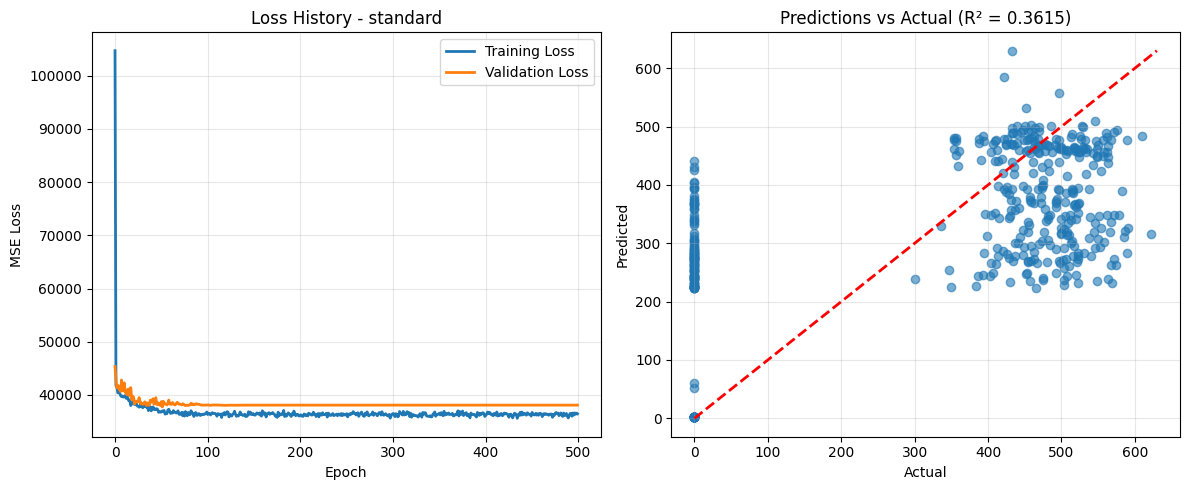

✅ standard scaler training completed successfully!

Training with scaler: minmax
Model initialized with input size: 11
Test Results - MSE: 34867.3242, RMSE: 186.7279, MAE: 149.4994, R²: 0.3369


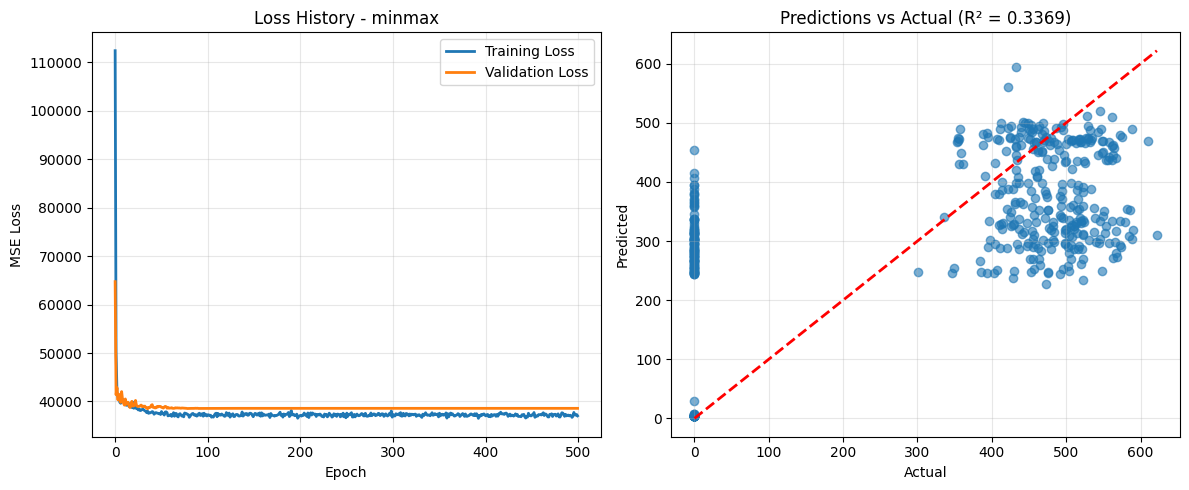

✅ minmax scaler training completed successfully!

Training with scaler: robust
Model initialized with input size: 11
Test Results - MSE: 34191.3516, RMSE: 184.9090, MAE: 147.7122, R²: 0.3497


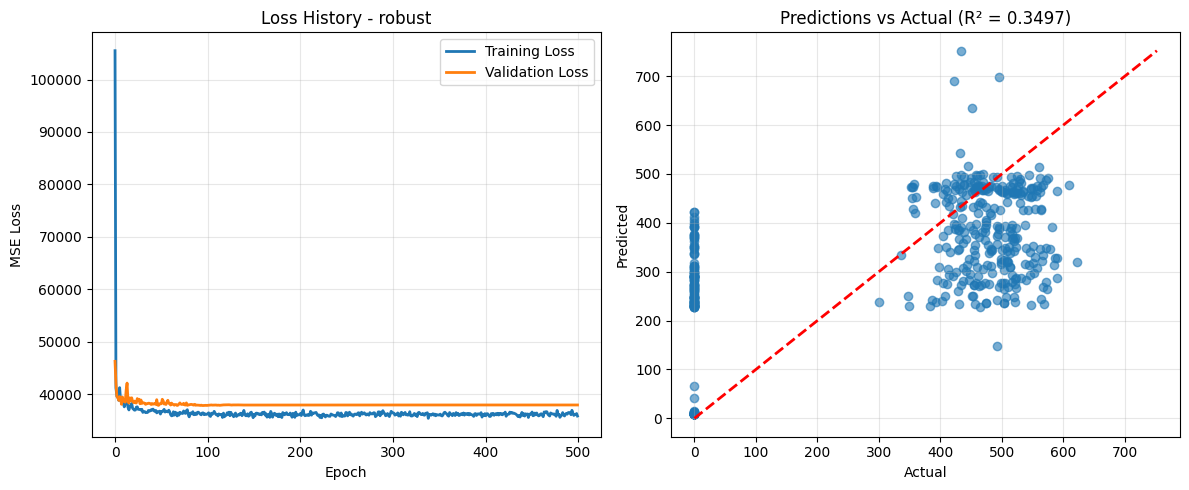

✅ robust scaler training completed successfully!

FINAL RESULTS SUMMARY
  scaler          mse       rmse        mae       r2                                   model_path                               scaler_path
standard 33574.179688 183.232584 146.127991 0.361460 /content/kochi_models/reg_model_standard.pth /content/kochi_models/scaler_standard.pkl
  robust 34191.351562 184.909036 147.712189 0.349723   /content/kochi_models/reg_model_robust.pth   /content/kochi_models/scaler_robust.pkl
  minmax 34867.324219 186.727942 149.499359 0.336866   /content/kochi_models/reg_model_minmax.pth   /content/kochi_models/scaler_minmax.pkl

🏆 BEST MODEL: standard Scaler
   R²: 0.3615
   RMSE: 183.2326
   MAE: 146.1280

📊 Summary saved to: /content/kochi_models/training_summary.csv

TRAINING PIPELINE COMPLETED!

Usage: model, scaler = load_trained_model('standard')


In [ ]:


import os
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import random
import joblib
import warnings
warnings.filterwarnings('ignore')

# ---------------------------
# Reproducibility & device
# ---------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1) Load dataset
DATA_PATH = "/content/kochi_induction_dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Loaded dataset with shape:", df.shape)
print("Columns:", df.columns.tolist())

# 2) Basic preprocessing
df = df.copy()

target_col = "Daily_Km_Assigned"

# Drop textual columns
drop_possible = ['Date','Trainset','DecisionReason','FinalDecision','Stabling_Difficulty','Depot','Bay_Position']
to_drop = [c for c in drop_possible if c in df.columns]
if to_drop:
    print("Dropping columns:", to_drop)
    df = df.drop(columns=to_drop)

# Convert boolean columns to numeric
bool_candidates = ['Rolling_Valid','Signalling_Valid', 'Telecom_Valid', 'Any_Fitness_Invalid', 'Critical_JobCard']
for col in bool_candidates:
    if col in df.columns:
        df[col] = df[col].astype(int) if df[col].dtype == 'bool' else pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# Convert categorical columns
if 'Mileage_Label' in df.columns:
    df['Mileage_Label'] = df['Mileage_Label'].map({'Underused': 0,'Balanced':1, 'Overused': 2}).fillna(0)

if 'Cleaning_Slot_Scheduled' in df.columns:
    df['Cleaning_Slot_Scheduled'] = df['Cleaning_Slot_Scheduled'].map({'Scheduled': 1,'None':0}).fillna(0)

print("Preprocessed dataset head:")
print(df.head())

# ---------------------------
# 3) Prepare feature matrix X and target y
# ---------------------------
X_df = df.drop(columns=[target_col])
y = df[target_col].astype(float)

# Convert all features to numeric and handle NaNs properly
for col in X_df.columns:
    if X_df[col].dtype == 'object':
        X_df[col] = pd.to_numeric(X_df[col], errors='coerce')

print("Feature set shape:", X_df.shape, "Target shape:", y.shape)

# ---------------------------
# 4) Train/test split
# ---------------------------
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_df, y, test_size=0.10, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, random_state=SEED
)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# ---------------------------
# 5) Handle missing values properly
# ---------------------------
# Fill numeric NaNs with median of training data
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
median_train = X_train[numeric_cols].median()
X_train[numeric_cols] = X_train[numeric_cols].fillna(median_train)
X_val[numeric_cols] = X_val[numeric_cols].fillna(median_train)
X_test[numeric_cols] = X_test[numeric_cols].fillna(median_train)

# Ensure all data is numeric
X_train = X_train.astype(float)
X_val = X_val.astype(float)
X_test = X_test.astype(float)

print("After imputation, any NaNs in train?", X_train.isna().any().any())
print("After imputation, any NaNs in val?", X_val.isna().any().any())
print("After imputation, any NaNs in test?", X_test.isna().any().any())

# Remove any remaining rows with NaN values (just in case)
nan_mask_train = X_train.isna().any(axis=1)
nan_mask_val = X_val.isna().any(axis=1)
nan_mask_test = X_test.isna().any(axis=1)

if nan_mask_train.any():
    print(f"Removing {nan_mask_train.sum()} rows with NaNs from training set")
    X_train = X_train[~nan_mask_train]
    y_train = y_train[~nan_mask_train]

if nan_mask_val.any():
    print(f"Removing {nan_mask_val.sum()} rows with NaNs from validation set")
    X_val = X_val[~nan_mask_val]
    y_val = y_val[~nan_mask_val]

if nan_mask_test.any():
    print(f"Removing {nan_mask_test.sum()} rows with NaNs from test set")
    X_test = X_test[~nan_mask_test]
    y_test = y_test[~nan_mask_test]

print("Final shapes - Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# ---------------------------
# 6) Define model and training components
# ---------------------------
MODEL_SAVE_DIR = "/content/kochi_models"
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

class NumpyDataset(Dataset):
    def __init__(self, X_np, y_np):
        self.X = torch.tensor(X_np, dtype=torch.float32)
        self.y = torch.tensor(y_np, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class RegressionModel(nn.Module):
    def __init__(self, input_size):
        super(RegressionModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

def train_regression(model, train_loader, val_loader, epochs=500, lr=0.01, patience=20):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

    best_val_loss = float('inf')
    best_state = None
    history = {"train_loss": [], "val_loss": []}
    epochs_no_improve = 0

    for epoch in range(1, epochs+1):
        # Training
        model.train()
        train_losses = []
        for Xb, yb in train_loader:
            Xb = Xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()
            preds = model(Xb)
            loss = criterion(preds, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_losses.append(loss.item())

        # Validation
        model.eval()
        val_losses = []
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb = Xb.to(device)
                yb = yb.to(device)
                preds = model(Xb)
                loss = criterion(preds, yb)
                val_losses.append(loss.item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        scheduler.step(val_loss)

        '''# Early stopping check
        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = model.state_dict().copy()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epoch % 50 == 0 or epoch == 1 or epoch == epochs:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch {epoch:03d}/{epochs}  Train MSE: {train_loss:.4f}  Val MSE: {val_loss:.4f}  LR: {current_lr:.6e}")

        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch}; no improvement for {patience} epochs.")
            break'''

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

# ---------------------------
# 7) Main training loop
# ---------------------------
scaler_constructors = {
    "standard": StandardScaler(),
    "minmax": MinMaxScaler(),
    "robust": RobustScaler()
}

RESULTS = []

for scaler_name, scaler in scaler_constructors.items():
    print("\n" + "="*50)
    print(f"Training with scaler: {scaler_name}")
    print("="*50)

    try:
        # Scale the data
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        X_test_scaled = scaler.transform(X_test)

        # Create datasets
        batch_size = 64
        train_dataset = NumpyDataset(X_train_scaled, y_train.values)
        val_dataset = NumpyDataset(X_val_scaled, y_val.values)
        test_dataset = NumpyDataset(X_test_scaled, y_test.values)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        # Build and train model
        input_size = X_train_scaled.shape[1]
        model = RegressionModel(input_size)
        print(f"Model initialized with input size: {input_size}")

        model, history = train_regression(model, train_loader, val_loader, epochs=500, lr=0.01, patience=20)

        # Evaluate on test set
        model.eval()
        preds_list = []
        actuals_list = []
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb = Xb.to(device)
                yb = yb.to(device)
                preds = model(Xb)
                preds_list.append(preds.cpu().numpy())
                actuals_list.append(yb.cpu().numpy())

        preds_all = np.concatenate(preds_list).ravel()
        actuals_all = np.concatenate(actuals_list).ravel()

        # Calculate metrics
        mse = mean_squared_error(actuals_all, preds_all)
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(actuals_all, preds_all)
        r2 = r2_score(actuals_all, preds_all)

        print(f"Test Results - MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, R²: {r2:.4f}")

        # Save model and scaler
        model_path = os.path.join(MODEL_SAVE_DIR, f"reg_model_{scaler_name}.pth")
        torch.save({
            'model_state_dict': model.state_dict(),
            'input_size': input_size,
            'scaler_name': scaler_name
        }, model_path)

        scaler_path = os.path.join(MODEL_SAVE_DIR, f"scaler_{scaler_name}.pkl")
        joblib.dump(scaler, scaler_path)

        # Plot training history
        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.plot(history['train_loss'], label='Training Loss', linewidth=2)
        plt.plot(history['val_loss'], label='Validation Loss', linewidth=2)
        plt.title(f"Loss History - {scaler_name}")
        plt.xlabel("Epoch")
        plt.ylabel("MSE Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.scatter(actuals_all, preds_all, alpha=0.6)
        min_val = min(actuals_all.min(), preds_all.min())
        max_val = max(actuals_all.max(), preds_all.max())
        plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
        plt.xlabel("Actual")
        plt.ylabel("Predicted")
        plt.title(f"Predictions vs Actual (R² = {r2:.4f})")
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(os.path.join(MODEL_SAVE_DIR, f"results_{scaler_name}.png"), dpi=300, bbox_inches='tight')
        plt.show()

        # Save results
        RESULTS.append({
            "scaler": scaler_name,
            "mse": mse,
            "rmse": rmse,
            "mae": mae,
            "r2": r2,
            "model_path": model_path,
            "scaler_path": scaler_path
        })

        print(f"✅ {scaler_name} scaler training completed successfully!")

    except Exception as e:
        print(f"❌ Error with {scaler_name} scaler: {e}")
        import traceback
        traceback.print_exc()

# ---------------------------
# 8) Results summary
# ---------------------------
if RESULTS:
    results_df = pd.DataFrame(RESULTS)
    results_df = results_df.sort_values("r2", ascending=False)

    print("\n" + "="*60)
    print("FINAL RESULTS SUMMARY")
    print("="*60)
    print(results_df.to_string(index=False))

    best_model = results_df.iloc[0]
    print(f"\n🏆 BEST MODEL: {best_model['scaler']} Scaler")
    print(f"   R²: {best_model['r2']:.4f}")
    print(f"   RMSE: {best_model['rmse']:.4f}")
    print(f"   MAE: {best_model['mae']:.4f}")

    # Save summary
    summary_path = os.path.join(MODEL_SAVE_DIR, "training_summary.csv")
    results_df.to_csv(summary_path, index=False)
    print(f"\n📊 Summary saved to: {summary_path}")
else:
    print("❌ No models were successfully trained.")

print("\n" + "="*60)
print("TRAINING PIPELINE COMPLETED!")
print("="*60)

# Inference function
def load_trained_model(scaler_name, model_dir=MODEL_SAVE_DIR):
    """Load a trained model for inference"""
    model_path = os.path.join(model_dir, f"reg_model_{scaler_name}.pth")
    scaler_path = os.path.join(model_dir, f"scaler_{scaler_name}.pkl")

    if not os.path.exists(model_path):
        print(f"Model for {scaler_name} not found! Available models:")
        for file in os.listdir(model_dir):
            if file.startswith("reg_model_"):
                print(f"  - {file}")
        return None, None

    # Load scaler and model
    scaler = joblib.load(scaler_path)
    checkpoint = torch.load(model_path, map_location=device)

    model = RegressionModel(checkpoint['input_size'])
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()

    return model, scaler

print("\nUsage: model, scaler = load_trained_model('standard')")

In [ ]:
import torch
import joblib
import pandas as pd

# Reload scaler
scaler = joblib.load("/content/kochi_models/scaler_minmax.pkl")

# Reload model
from torch import nn
class Models(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.new_mod = nn.Sequential(
            nn.Linear(input_size,10),
            nn.LeakyReLU(0.2),
            nn.Linear(10,100),
            nn.LeakyReLU(0.2),
            nn.Linear(100,100),
            nn.LeakyReLU(0.2),
            nn.Linear(100,100),
            nn.Tanh(),
            nn.Linear(100,1)
        )
    def forward(self, x): return self.new_mod(x)

model = Models(input_size=10)
model.load_state_dict(torch.load("/content/kochi_models/reg_model_minmax.pth", map_location="cpu"))
model.eval()

# Predict on new data
X_new = pd.DataFrame([...])  # must preprocess same way
X_scaled = scaler.transform(X_new.values)
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)

with torch.no_grad():
    preds = model(X_tensor).numpy()
print(preds)


RuntimeError: Error(s) in loading state_dict for Models:
	Missing key(s) in state_dict: "new_mod.0.weight", "new_mod.0.bias", "new_mod.2.weight", "new_mod.2.bias", "new_mod.4.weight", "new_mod.4.bias", "new_mod.6.weight", "new_mod.6.bias", "new_mod.8.weight", "new_mod.8.bias". 
	Unexpected key(s) in state_dict: "model_state_dict", "input_size", "scaler_name". 

In [ ]:
# Load a trained model
model, scaler = load_trained_model('standard')

# Prepare a specific input sample (using first test sample as example)
sample_input = X_test.iloc[0:1]  # Get first row as DataFrame
sample_actual = y_test.iloc[0]

print("Sample input features:")
print(sample_input)
print(f"Actual target: {sample_actual}")

# Transform the sample using the scaler
sample_scaled = scaler.transform(sample_input)

# Convert to tensor and get prediction
sample_tensor = torch.tensor(sample_scaled, dtype=torch.float32).to(device)
model.eval()
with torch.no_grad():
    prediction = model(sample_tensor)

print(f"Model prediction: {prediction.item():.4f}")
print(f"Difference: {abs(prediction.item() - sample_actual):.4f}")

Sample input features:
      Rolling_Valid  Signalling_Valid  Telecom_Valid  Any_Fitness_Invalid  \
2323            1.0               1.0            1.0                  0.0   

      Open_JobCards  Critical_JobCard  Branding_Hours_Left  Cum_Mileage  \
2323            0.0               0.0                  0.0      52808.0   

      Mileage_Label  Days_Since_Last_Deep_Clean  Cleaning_Slot_Scheduled  
2323            0.0                        10.0                      0.0  
Actual target: 478.0
Model prediction: 469.6693
Difference: 8.3307


Loaded dataset with shape: (4500, 19)
Columns: ['Date', 'Trainset', 'Depot', 'FinalDecision', 'DecisionReason', 'Rolling_Valid', 'Signalling_Valid', 'Telecom_Valid', 'Any_Fitness_Invalid', 'Open_JobCards', 'Critical_JobCard', 'Branding_Hours_Left', 'Cum_Mileage', 'Mileage_Label', 'Days_Since_Last_Deep_Clean', 'Cleaning_Slot_Scheduled', 'Bay_Position', 'Stabling_Difficulty', 'Daily_Km_Assigned']
Dropping columns: ['Date', 'Trainset', 'DecisionReason', 'FinalDecision', 'Stabling_Difficulty', 'Depot', 'Bay_Position']
Preprocessed dataset head:
   Rolling_Valid  Signalling_Valid  Telecom_Valid  Any_Fitness_Invalid  \
0              1                 1              1                    0   
1              1                 1              1                    0   
2              1                 1              1                    0   
3              1                 1              1                    0   
4              1                 1              1                    0   

   Open_

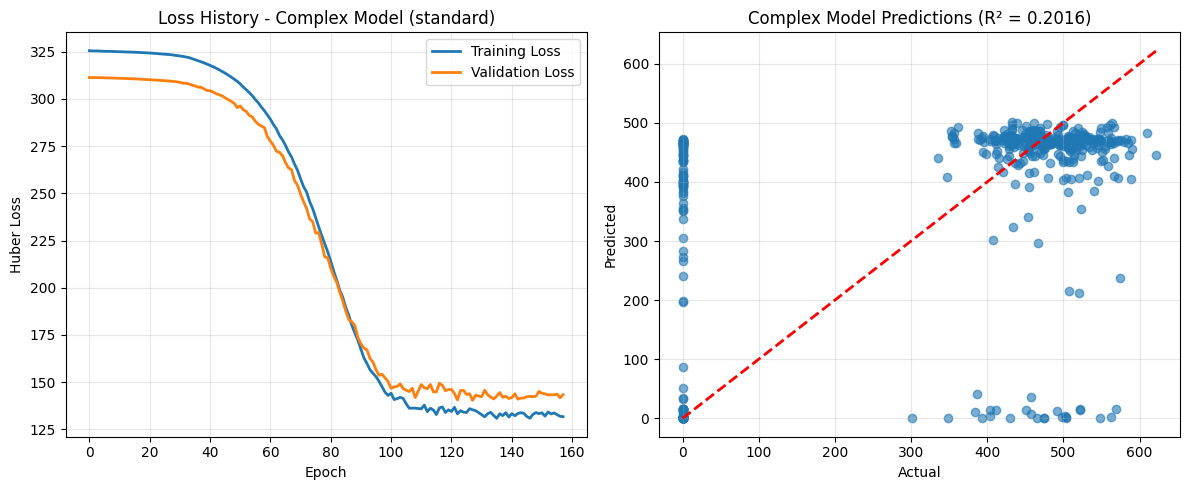

✅ COMPLEX standard scaler training completed successfully!

Training with COMPLEX model and scaler: minmax
Model initialized with input size: 11
Total parameters: 1,048,471
Trainable parameters: 1,048,471
Epoch 001/1000  Train Loss: 325.6216  Val Loss: 311.2911  LR: 4.023693e-05
Epoch 020/1000  Train Loss: 324.4633  Val Loss: 310.3911  LR: 1.317030e-04
Epoch 040/1000  Train Loss: 320.6025  Val Loss: 306.6965  LR: 3.717725e-04
Epoch 060/1000  Train Loss: 301.9594  Val Loss: 289.4308  LR: 6.684791e-04
Epoch 080/1000  Train Loss: 252.5500  Val Loss: 242.5582  LR: 9.084525e-04
Epoch 100/1000  Train Loss: 172.4135  Val Loss: 171.5568  LR: 1.000000e-03
Epoch 120/1000  Train Loss: 136.8078  Val Loss: 144.0331  LR: 9.987799e-04
Epoch 140/1000  Train Loss: 133.6349  Val Loss: 145.7272  LR: 9.951298e-04
Epoch 160/1000  Train Loss: 132.5388  Val Loss: 142.6545  LR: 9.890675e-04
Early stopping at epoch 174; no improvement for 30 epochs.

🚀 COMPLEX MODEL Test Results:
   MSE: 39564.1680
   RMSE: 19

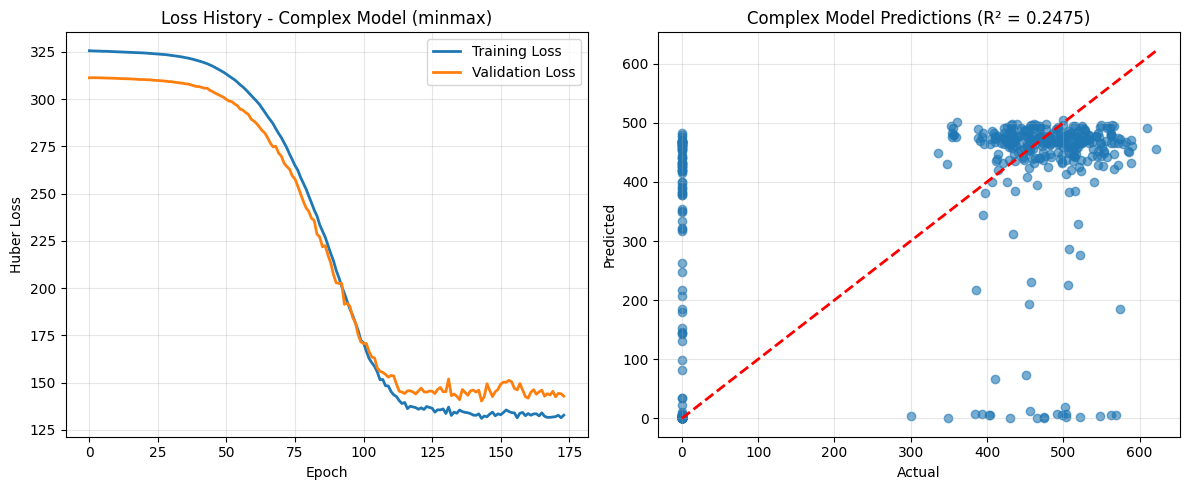

✅ COMPLEX minmax scaler training completed successfully!

Training with COMPLEX model and scaler: robust
Model initialized with input size: 11
Total parameters: 1,048,471
Trainable parameters: 1,048,471
Epoch 001/1000  Train Loss: 325.2931  Val Loss: 311.1096  LR: 4.023693e-05
Epoch 020/1000  Train Loss: 323.9693  Val Loss: 310.0051  LR: 1.317030e-04
Epoch 040/1000  Train Loss: 318.8176  Val Loss: 305.3777  LR: 3.717725e-04
Epoch 060/1000  Train Loss: 293.2800  Val Loss: 281.2385  LR: 6.684791e-04
Epoch 080/1000  Train Loss: 226.6706  Val Loss: 223.8020  LR: 9.084525e-04
Epoch 100/1000  Train Loss: 145.6191  Val Loss: 152.3072  LR: 1.000000e-03
Epoch 120/1000  Train Loss: 135.0589  Val Loss: 153.4305  LR: 9.987799e-04
Epoch 140/1000  Train Loss: 133.3206  Val Loss: 146.3506  LR: 9.951298e-04
Epoch 160/1000  Train Loss: 133.4029  Val Loss: 144.7604  LR: 9.890675e-04
Early stopping at epoch 168; no improvement for 30 epochs.

🚀 COMPLEX MODEL Test Results:
   MSE: 38590.9297
   RMSE: 196.

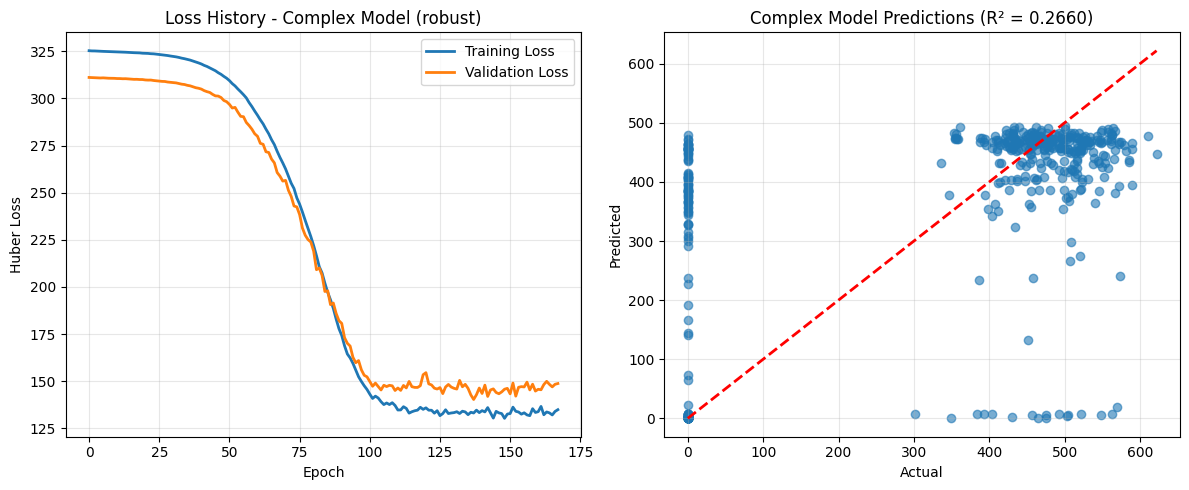

✅ COMPLEX robust scaler training completed successfully!

FINAL COMPLEX MODELS RESULTS SUMMARY
  scaler          mse       rmse        mae       r2                                                         model_path                                       scaler_path  parameters
  robust 38590.929688 196.445742 123.859177 0.266048   /content/kochi_complex_models/ultra_complex_reg_model_robust.pth   /content/kochi_complex_models/scaler_robust.pkl     1048471
  minmax 39564.167969 198.907436 121.020439 0.247538   /content/kochi_complex_models/ultra_complex_reg_model_minmax.pth   /content/kochi_complex_models/scaler_minmax.pkl     1048471
standard 41977.414062 204.883904 124.980469 0.201641 /content/kochi_complex_models/ultra_complex_reg_model_standard.pth /content/kochi_complex_models/scaler_standard.pkl     1048471

🏆 BEST COMPLEX MODEL: robust Scaler
   R²: 0.2660
   RMSE: 196.4457
   MAE: 123.8592
   Parameters: 1,048,471

📊 Summary saved to: /content/kochi_complex_models/complex_trainin

In [ ]:
# Running a full from-scratch regression training pipeline on your Kochi dataset.
# - Target: Daily_Km_Assigned (regression)
# - We will try three feature-scaling strategies: StandardScaler, MinMaxScaler, RobustScaler
# - For each scaler: fit scaler only on training data, train a complex PyTorch regression model, use early stopping,
#   plot train/val loss, plot predicted vs actual on test set, and save best model.

import os
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import random
import joblib
import warnings
warnings.filterwarnings('ignore')

# ---------------------------
# Reproducibility & device
# ---------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1) Load dataset
DATA_PATH = "/content/kochi_induction_dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Loaded dataset with shape:", df.shape)
print("Columns:", df.columns.tolist())

# 2) Basic preprocessing
df = df.copy()

target_col = "Daily_Km_Assigned"

# Drop textual columns
drop_possible = ['Date','Trainset','DecisionReason','FinalDecision','Stabling_Difficulty','Depot','Bay_Position']
to_drop = [c for c in drop_possible if c in df.columns]
if to_drop:
    print("Dropping columns:", to_drop)
    df = df.drop(columns=to_drop)

# Convert boolean columns to numeric
bool_candidates = ['Rolling_Valid','Signalling_Valid', 'Telecom_Valid', 'Any_Fitness_Invalid', 'Critical_JobCard']
for col in bool_candidates:
    if col in df.columns:
        df[col] = df[col].astype(int) if df[col].dtype == 'bool' else pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# Convert categorical columns
if 'Mileage_Label' in df.columns:
    df['Mileage_Label'] = df['Mileage_Label'].map({'Underused': 0,'Balanced':1, 'Overused': 2}).fillna(0)

if 'Cleaning_Slot_Scheduled' in df.columns:
    df['Cleaning_Slot_Scheduled'] = df['Cleaning_Slot_Scheduled'].map({'Scheduled': 1,'None':0}).fillna(0)

print("Preprocessed dataset head:")
print(df.head())

# ---------------------------
# 3) Prepare feature matrix X and target y
# ---------------------------
X_df = df.drop(columns=[target_col])
y = df[target_col].astype(float)

# Convert all features to numeric and handle NaNs properly
for col in X_df.columns:
    if X_df[col].dtype == 'object':
        X_df[col] = pd.to_numeric(X_df[col], errors='coerce')

print("Feature set shape:", X_df.shape, "Target shape:", y.shape)

# ---------------------------
# 4) Train/test split
# ---------------------------
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_df, y, test_size=0.10, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, random_state=SEED
)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# ---------------------------
# 5) Handle missing values properly
# ---------------------------
# Fill numeric NaNs with median of training data
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
median_train = X_train[numeric_cols].median()
X_train[numeric_cols] = X_train[numeric_cols].fillna(median_train)
X_val[numeric_cols] = X_val[numeric_cols].fillna(median_train)
X_test[numeric_cols] = X_test[numeric_cols].fillna(median_train)

# Ensure all data is numeric
X_train = X_train.astype(float)
X_val = X_val.astype(float)
X_test = X_test.astype(float)

print("After imputation, any NaNs in train?", X_train.isna().any().any())
print("After imputation, any NaNs in val?", X_val.isna().any().any())
print("After imputation, any NaNs in test?", X_test.isna().any().any())

# Remove any remaining rows with NaN values (just in case)
nan_mask_train = X_train.isna().any(axis=1)
nan_mask_val = X_val.isna().any(axis=1)
nan_mask_test = X_test.isna().any(axis=1)

if nan_mask_train.any():
    print(f"Removing {nan_mask_train.sum()} rows with NaNs from training set")
    X_train = X_train[~nan_mask_train]
    y_train = y_train[~nan_mask_train]

if nan_mask_val.any():
    print(f"Removing {nan_mask_val.sum()} rows with NaNs from validation set")
    X_val = X_val[~nan_mask_val]
    y_val = y_val[~nan_mask_val]

if nan_mask_test.any():
    print(f"Removing {nan_mask_test.sum()} rows with NaNs from test set")
    X_test = X_test[~nan_mask_test]
    y_test = y_test[~nan_mask_test]

print("Final shapes - Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# ---------------------------
# 6) Define COMPLEX model and training components
# ---------------------------
MODEL_SAVE_DIR = "/content/kochi_complex_models"
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

class NumpyDataset(Dataset):
    def __init__(self, X_np, y_np):
        self.X = torch.tensor(X_np, dtype=torch.float32)
        self.y = torch.tensor(y_np, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class ComplexRegressionModel(nn.Module):
    def __init__(self, input_size):
        super(ComplexRegressionModel, self).__init__()

        # Main deep network with residual connections
        self.block1 = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3)
        )

        self.block2 = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3)
        )

        self.block3 = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2)
        )

        self.block4 = nn.Sequential(
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2)
        )

        self.block5 = nn.Sequential(
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.1)
        )

        # Attention mechanism for feature importance
        self.attention = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

        # Multiple output heads for different aspects
        self.output_head1 = nn.Linear(32, 16)
        self.output_head2 = nn.Linear(16, 8)
        self.final_output = nn.Linear(8, 1)

        # Skip connections
        self.skip1 = nn.Linear(input_size, 256) if input_size != 256 else nn.Identity()
        self.skip2 = nn.Linear(256, 128) if 256 != 128 else nn.Identity()

        # Layer normalization
        self.ln1 = nn.LayerNorm(512)
        self.ln2 = nn.LayerNorm(256)
        self.ln3 = nn.LayerNorm(128)
        self.ln4 = nn.LayerNorm(64)
        self.ln5 = nn.LayerNorm(32)

    def forward(self, x):
        # Apply attention to input features
        attention_weights = self.attention(x)
        x_attended = x * attention_weights

        # Main forward pass with residual connections
        out1 = self.ln1(self.block1(x_attended))

        out2 = self.ln2(self.block2(out1))

        out3 = self.ln3(self.block3(out2) + self.skip1(x_attended))

        out4 = self.ln4(self.block4(out3))

        out5 = self.ln5(self.block5(out4) + self.skip2(out2))

        # Output heads
        out = nn.functional.leaky_relu(self.output_head1(out5), 0.1)
        out = nn.functional.leaky_relu(self.output_head2(out), 0.1)
        out = self.final_output(out)

        return out.squeeze(1)

class UltraComplexRegressionModel(nn.Module):
    def __init__(self, input_size):
        super(UltraComplexRegressionModel, self).__init__()

        # Even more complex architecture with multiple pathways
        self.input_bn = nn.BatchNorm1d(input_size)

        # Pathway 1: Deep main network
        self.main_path = nn.Sequential(
            nn.Linear(input_size, 1024),
            nn.BatchNorm1d(1024),
            nn.GELU(),
            nn.Dropout(0.4),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        # Pathway 2: Wide network
        self.wide_path = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        # Pathway 3: Feature interactions
        self.interaction_path = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        # Combine all pathways
        combined_size = 64 + 256 + 128
        self.combiner = nn.Sequential(
            nn.Linear(combined_size, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.1),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.GELU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.input_bn(x)

        # Main pathway
        main_out = self.main_path(x)

        # Wide pathway
        wide_out = self.wide_path(x)

        # Interaction pathway
        interaction_out = self.interaction_path(x)

        # Combine all pathways
        combined = torch.cat([main_out, wide_out, interaction_out], dim=1)
        output = self.combiner(combined)

        return output.squeeze(1)

def train_complex_regression(model, train_loader, val_loader, epochs=1000, lr=0.001, patience=30):
    model = model.to(device)
    criterion = nn.HuberLoss(delta=1.0)  # More robust than MSE
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    # More sophisticated learning rate scheduler
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=lr,
        epochs=epochs,
        steps_per_epoch=len(train_loader),
        pct_start=0.1
    )

    best_val_loss = float('inf')
    best_state = None
    history = {"train_loss": [], "val_loss": []}
    epochs_no_improve = 0

    for epoch in range(1, epochs+1):
        # Training
        model.train()
        train_losses = []
        for Xb, yb in train_loader:
            Xb = Xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()
            preds = model(Xb)
            loss = criterion(preds, yb)
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()

            train_losses.append(loss.item())

        # Validation
        model.eval()
        val_losses = []
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb = Xb.to(device)
                yb = yb.to(device)
                preds = model(Xb)
                loss = criterion(preds, yb)
                val_losses.append(loss.item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Early stopping check
        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = model.state_dict().copy()
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epoch % 20 == 0 or epoch == 1 or epoch == epochs:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch {epoch:03d}/{epochs}  Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f}  LR: {current_lr:.6e}")

        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch}; no improvement for {patience} epochs.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

# ---------------------------
# 7) Main training loop with COMPLEX models
# ---------------------------
scaler_constructors = {
    "standard": StandardScaler(),
    "minmax": MinMaxScaler(),
    "robust": RobustScaler()
}

RESULTS = []

for scaler_name, scaler in scaler_constructors.items():
    print("\n" + "="*60)
    print(f"Training with COMPLEX model and scaler: {scaler_name}")
    print("="*60)

    try:
        # Scale the data
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        X_test_scaled = scaler.transform(X_test)

        # Create datasets
        batch_size = 64
        train_dataset = NumpyDataset(X_train_scaled, y_train.values)
        val_dataset = NumpyDataset(X_val_scaled, y_val.values)
        test_dataset = NumpyDataset(X_test_scaled, y_test.values)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        # Build and train ULTRA COMPLEX model
        input_size = X_train_scaled.shape[1]
        model = UltraComplexRegressionModel(input_size)

        # Count parameters
        total_params = sum(p.numel() for p in model.parameters())
        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Model initialized with input size: {input_size}")
        print(f"Total parameters: {total_params:,}")
        print(f"Trainable parameters: {trainable_params:,}")

        model, history = train_complex_regression(model, train_loader, val_loader, epochs=1000, lr=0.001, patience=30)

        # Evaluate on test set
        model.eval()
        preds_list = []
        actuals_list = []
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb = Xb.to(device)
                yb = yb.to(device)
                preds = model(Xb)
                preds_list.append(preds.cpu().numpy())
                actuals_list.append(yb.cpu().numpy())

        preds_all = np.concatenate(preds_list).ravel()
        actuals_all = np.concatenate(actuals_list).ravel()

        # Calculate metrics
        mse = mean_squared_error(actuals_all, preds_all)
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(actuals_all, preds_all)
        r2 = r2_score(actuals_all, preds_all)

        print(f"\n🚀 COMPLEX MODEL Test Results:")
        print(f"   MSE: {mse:.4f}")
        print(f"   RMSE: {rmse:.4f}")
        print(f"   MAE: {mae:.4f}")
        print(f"   R²: {r2:.4f}")

        # Save model and scaler
        model_path = os.path.join(MODEL_SAVE_DIR, f"ultra_complex_reg_model_{scaler_name}.pth")
        torch.save({
            'model_state_dict': model.state_dict(),
            'input_size': input_size,
            'scaler_name': scaler_name
        }, model_path)

        scaler_path = os.path.join(MODEL_SAVE_DIR, f"scaler_{scaler_name}.pkl")
        joblib.dump(scaler, scaler_path)

        # Plot training history
        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.plot(history['train_loss'], label='Training Loss', linewidth=2)
        plt.plot(history['val_loss'], label='Validation Loss', linewidth=2)
        plt.title(f"Loss History - Complex Model ({scaler_name})")
        plt.xlabel("Epoch")
        plt.ylabel("Huber Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.scatter(actuals_all, preds_all, alpha=0.6)
        min_val = min(actuals_all.min(), preds_all.min())
        max_val = max(actuals_all.max(), preds_all.max())
        plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
        plt.xlabel("Actual")
        plt.ylabel("Predicted")
        plt.title(f"Complex Model Predictions (R² = {r2:.4f})")
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(os.path.join(MODEL_SAVE_DIR, f"complex_results_{scaler_name}.png"), dpi=300, bbox_inches='tight')
        plt.show()

        # Save results
        RESULTS.append({
            "scaler": scaler_name,
            "mse": mse,
            "rmse": rmse,
            "mae": mae,
            "r2": r2,
            "model_path": model_path,
            "scaler_path": scaler_path,
            "parameters": total_params
        })

        print(f"✅ COMPLEX {scaler_name} scaler training completed successfully!")

    except Exception as e:
        print(f"❌ Error with complex {scaler_name} scaler: {e}")
        import traceback
        traceback.print_exc()

# ---------------------------
# 8) Results summary
# ---------------------------
if RESULTS:
    results_df = pd.DataFrame(RESULTS)
    results_df = results_df.sort_values("r2", ascending=False)

    print("\n" + "="*70)
    print("FINAL COMPLEX MODELS RESULTS SUMMARY")
    print("="*70)
    print(results_df.to_string(index=False))

    best_model = results_df.iloc[0]
    print(f"\n🏆 BEST COMPLEX MODEL: {best_model['scaler']} Scaler")
    print(f"   R²: {best_model['r2']:.4f}")
    print(f"   RMSE: {best_model['rmse']:.4f}")
    print(f"   MAE: {best_model['mae']:.4f}")
    print(f"   Parameters: {best_model['parameters']:,}")

    # Save summary
    summary_path = os.path.join(MODEL_SAVE_DIR, "complex_training_summary.csv")
    results_df.to_csv(summary_path, index=False)
    print(f"\n📊 Summary saved to: {summary_path}")
else:
    print("❌ No complex models were successfully trained.")

print("\n" + "="*70)
print("COMPLEX MODEL TRAINING PIPELINE COMPLETED!")
print("="*70)

# Enhanced inference function
def load_complex_model(scaler_name, model_dir=MODEL_SAVE_DIR):
    """Load a trained complex model for inference"""
    model_path = os.path.join(model_dir, f"ultra_complex_reg_model_{scaler_name}.pth")
    scaler_path = os.path.join(model_dir, f"scaler_{scaler_name}.pkl")

    if not os.path.exists(model_path):
        print(f"Complex model for {scaler_name} not found! Available models:")
        for file in os.listdir(model_dir):
            if file.startswith("ultra_complex_reg_model_"):
                print(f"  - {file}")
        return None, None

    # Load scaler and model
    scaler = joblib.load(scaler_path)
    checkpoint = torch.load(model_path, map_location=device)

    model = UltraComplexRegressionModel(checkpoint['input_size'])
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()

    return model, scaler

print("\nUsage: model, scaler = load_complex_model('standard')")

In [ ]:
pdi.head(5)

,Depot,FinalDecision,Rolling_Valid,Signalling_Valid,Telecom_Valid,Any_Fitness_Invalid,Open_JobCards,Critical_JobCard,Branding_Hours_Left,Cum_Mileage,Mileage_Label,Days_Since_Last_Deep_Clean,Cleaning_Slot_Scheduled,Bay_Position,Stabling_Difficulty,Daily_Km_Assigned
0,DepotB,1.0,1,1,1,0,0,0,0,20745,0.0,12,0.0,15,1,506
1,DepotA,1.0,1,1,1,0,0,0,253,38560,1.0,15,1.0,23,2,543
2,DepotA,1.0,1,1,1,0,1,0,82,23293,0.0,16,1.0,20,1,601
3,DepotA,1.0,1,1,1,0,0,0,0,25734,0.0,10,0.0,29,2,673
4,DepotA,0.0,1,1,1,0,0,0,0,36381,1.0,8,0.0,2,0,0


In [ ]:
# Improved end-to-end pipeline (LightGBM + stacked PyTorch MLP)
# Copy into your notebook and run. Replace DATA_PATH if needed.

import os, math, random, warnings
from typing import List
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_PATH = "/content/Copy of output_mileage_mtd_scored(1).csv"  # change if needed
TARGET = "score"  # keep same as yours

# ------------------------
# Helper functions
# ------------------------
def print_metrics(y_true, y_pred, prefix=""):
    mse = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{prefix}MSE: {mse:.6f} | RMSE: {rmse:.6f} | MAE: {mae:.6f} | R2: {r2:.6f}")
    return {"mse": mse, "rmse": rmse, "mae": mae, "r2": r2}

def winsorize_series(s: pd.Series, lower_q=0.01, upper_q=0.99):
    lo, hi = s.quantile(lower_q), s.quantile(upper_q)
    return s.clip(lo, hi)

# ------------------------
# Load & quick inspect
# ------------------------
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "shape:", df.shape)
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns: {df.columns.tolist()}")

# Drop pure-identifier columns if they are obviously IDs (heuristic)
# (You can tweak or remove this)
for c in df.columns:
    if c.lower() in ["id", "index", "serial"]:
        df = df.drop(columns=[c], errors="ignore")

# ------------------------
# Preprocessing: automatic, safe, uses ALL columns
# ------------------------
def preprocess_frame(df: pd.DataFrame, target_col: str, clip_q=(0.01, 0.99), treat_small_cardinality_as_cat=30):
    df = df.copy()
    # keep original order
    original_cols = df.columns.tolist()
    # 1) convert obvious numeric strings -> numeric
    for c in df.columns:
        if df[c].dtype == "object":
            # try numeric conversion (coerce)
            coerced = pd.to_numeric(df[c], errors="coerce")
            # accept conversion if a majority become numeric
            if coerced.notna().sum() >= 0.5 * len(coerced):
                df[c] = coerced
            else:
                # try parse date
                try:
                    parsed = pd.to_datetime(df[c], errors="coerce")
                    if parsed.notna().sum() >= 0.5 * len(parsed):
                        df[c] = parsed
                except Exception:
                    pass

    # 2) Extract datetime features for datetime columns
    date_cols = df.select_dtypes(include=["datetime", "datetimetz"]).columns.tolist()
    for c in date_cols:
        df[c+"_year"] = df[c].dt.year.fillna(0).astype(int)
        df[c+"_month"] = df[c].dt.month.fillna(0).astype(int)
        df[c+"_day"] = df[c].dt.day.fillna(0).astype(int)
        df[c+"_weekday"] = df[c].dt.weekday.fillna(0).astype(int)
        # drop original datetime to avoid complexity (optional)
        df = df.drop(columns=[c])

    # 3) Normalize booleans
    for c in df.columns:
        if df[c].dtype == "bool":
            df[c] = df[c].astype(int)

    # 4) Identify numeric vs categorical
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if target_col in numeric_cols:
        numeric_cols.remove(target_col)
    # Consider small-unique-count ints as categorical
    possible_cat = []
    for c in df.columns:
        if c == target_col:
            continue
        if df[c].dtype == "object":
            possible_cat.append(c)
        elif df[c].dtype in [np.int64, np.int32, np.int16, np.int8]:
            if df[c].nunique(dropna=True) <= treat_small_cardinality_as_cat:
                possible_cat.append(c)

    categorical_cols = list(set(possible_cat))
    # Ensure no overlap
    numeric_cols = [c for c in numeric_cols if c not in categorical_cols]

    # 5) Fill numeric NaNs and winsorize
    for c in numeric_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
        med = df[c].median()
        df[c] = df[c].fillna(med)
        # winsorize to reduce huge outliers
        if df[c].nunique() > 5:
            df[c] = winsorize_series(df[c], lower_q=clip_q[0], upper_q=clip_q[1])

    # 6) Fill categorical NaNs and encode with category codes (safe for trees)
    for c in categorical_cols:
        df[c] = df[c].astype(str).fillna("__missing__")
        df[c] = pd.Categorical(df[c])
        df[c+"_code"] = df[c].cat.codes  # -1 not expected because filled, codes start from 0
    # drop originals for categorical columns
    df = df.drop(columns=categorical_cols, errors="ignore")

    # 7) Drop columns with constant values
    drops = [c for c in df.columns if df[c].nunique() <= 1 and c != target_col]
    if drops:
        df = df.drop(columns=drops)

    # 8) Final numeric feature list (exclude target)
    final_features = [c for c in df.columns if c != target_col]
    return df[final_features + [target_col]].copy(), final_features

df_proc, features = preprocess_frame(df, TARGET)
print("After preprocessing shape:", df_proc.shape, "feature count:", len(features))

# ------------------------
# Prepare arrays for modelling
# ------------------------
X = df_proc[features].values.astype(float)
y = df_proc[TARGET].values.astype(float)

# Train/val/test splits (same fractions as your original)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=SEED)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# ------------------------
# Fit a strong tree model with CV (LightGBM if available)
# ------------------------
USE_LGB = False
USE_XGB = False
try:
    import lightgbm as lgb
    USE_LGB = True
except Exception:
    print("lightgbm not installed -> fallback to RandomForest")

try:
    import xgboost as xgb
    USE_XGB = True
except Exception:
    print("xgboost not installed or not used")

oof_preds = np.zeros_like(y_train, dtype=float)
test_preds_lgb = np.zeros(len(y_test), dtype=float)
val_preds_lgb = np.zeros(len(y_val), dtype=float)

if USE_LGB:
    params = {
        "objective": "regression",
        "metric": "rmse",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "verbosity": -1,
        "seed": SEED,
        "lambda_l1": 0.1,
        "lambda_l2": 0.1
    }
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    val_idx_offset = 0
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X_train, y_train)):
        print(f"\nLGB fold {fold+1}/5")
        dtrain = lgb.Dataset(X_train[tr_idx], label=y_train[tr_idx])
        dvalid = lgb.Dataset(X_train[va_idx], label=y_train[va_idx], reference=dtrain)
        bst = lgb.train(params,
                        dtrain,
                        num_boost_round=5000,
                        valid_sets=[dtrain, dvalid],
                        early_stopping_rounds=200,
                        verbose_eval=200)
        # OOF
        oof_preds[va_idx] = bst.predict(X_train[va_idx], num_iteration=bst.best_iteration)
        # val and test preds accumulation
        val_preds_lgb += bst.predict(X_val, num_iteration=bst.best_iteration) / kf.n_splits
        test_preds_lgb += bst.predict(X_test, num_iteration=bst.best_iteration) / kf.n_splits

    print("\nLGB OOF metrics:")
    print_metrics(y_train, oof_preds, prefix="OOF ")
else:
    # fallback: RandomForest with OOF (simple)
    print("Training RandomForest (fallback)")
    from sklearn.model_selection import KFold
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    rf_test = np.zeros(len(y_test))
    rf_val = np.zeros(len(y_val))
    oof_preds = np.zeros_like(y_train)
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X_train, y_train)):
        print(f"RF fold {fold+1}/5")
        model = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
        model.fit(X_train[tr_idx], y_train[tr_idx])
        oof_preds[va_idx] = model.predict(X_train[va_idx])
        rf_val += model.predict(X_val) / kf.n_splits
        rf_test += model.predict(X_test) / kf.n_splits
    val_preds_lgb = rf_val
    test_preds_lgb = rf_test
    print_metrics(y_train, oof_preds, prefix="OOF ")


# OOF predictions are ready — we'll use them as an extra feature for the MLP (stacking)
# Prepare stacked training data (append OOF pred as a new column)
X_train_stack = np.hstack([X_train, oof_preds.reshape(-1,1)])
X_val_stack   = np.hstack([X_val, val_preds_lgb.reshape(-1,1)])
X_test_stack  = np.hstack([X_test, test_preds_lgb.reshape(-1,1)])

# Standardize for MLP
scaler = StandardScaler()
X_train_stack_scaled = scaler.fit_transform(X_train_stack)
X_val_stack_scaled   = scaler.transform(X_val_stack)
X_test_stack_scaled  = scaler.transform(X_test_stack)

# ------------------------
# PyTorch MLP (stacking model)
# ------------------------
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class MLPRegressor(nn.Module):
    def __init__(self, input_dim, hidden=[256,128], dropout=0.2):
        super().__init__()
        layers = []
        in_dim = input_dim
        for h in hidden:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

def train_mlp(model, X_tr, y_tr, X_val, y_val, epochs=200, lr=1e-3, batch_size=64, patience=20):
    model.to(device)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    train_ds = TabularDataset(X_tr, y_tr)
    val_ds = TabularDataset(X_val, y_val)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    best_val = float("inf")
    best_state = None
    stale = 0
    for ep in range(1, epochs+1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            opt.step()
            train_losses.append(loss.item())
        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                val_losses.append(loss_fn(out, yb).item())
        avg_val = np.mean(val_losses)
        if ep % 25 == 0 or ep == 1:
            print(f"Epoch {ep} | TrainLoss {np.mean(train_losses):.6f} | ValLoss {avg_val:.6f}")
        if avg_val < best_val:
            best_val = avg_val
            best_state = {k:v.cpu() for k,v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                print("MLP early stopping at epoch", ep)
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model

mlp = MLPRegressor(input_dim=X_train_stack_scaled.shape[1], hidden=[256,128], dropout=0.25)
mlp = train_mlp(mlp, X_train_stack_scaled, y_train, X_val_stack_scaled, y_val, epochs=400, lr=1e-3, batch_size=64, patience=40)

# Evaluate MLP
mlp.eval()
with torch.no_grad():
    preds_val_mlp = mlp(torch.tensor(X_val_stack_scaled, dtype=torch.float32).to(device)).cpu().numpy()
    preds_test_mlp = mlp(torch.tensor(X_test_stack_scaled, dtype=torch.float32).to(device)).cpu().numpy()

print("\nValidation metrics:")
print_metrics(y_val, val_preds_lgb, prefix="LGB Val: ")   # tree val (averaged CV)
print_metrics(y_val, preds_val_mlp, prefix="MLP Val: ")
# Ensemble: average
ens_val = 0.5 * val_preds_lgb + 0.5 * preds_val_mlp
print_metrics(y_val, ens_val, prefix="Ensemble Val: ")

# Final test evaluation
print("\nTest metrics:")
print_metrics(y_test, test_preds_lgb, prefix="LGB Test: ")
print_metrics(y_test, preds_test_mlp, prefix="MLP Test: ")
ens_test = 0.5 * test_preds_lgb + 0.5 * preds_test_mlp
print_metrics(y_test, ens_test, prefix="Ensemble Test: ")

# ------------------------
# Save artifacts
# ------------------------
import joblib
joblib.dump(scaler, "stack_scaler.joblib")
try:
    if USE_LGB:
        bst.save_model("lgb_model.txt")
        print("Saved lgb_model.txt")
except Exception:
    pass
torch.save(mlp.state_dict(), "mlp_stack.pth")
print("Saved mlp_stack.pth and scaler")

# ------------------------
# Quick feature importance (if LGB used)
# ------------------------
if USE_LGB:
    print("\nTop features by LightGBM importance (approx):")
    try:
        importance = bst.feature_importance(importance_type="gain")
        names = features + ["lgb_oof_pred"]
        imp_df = pd.DataFrame({"feature": names, "importance": importance})
        imp_df = imp_df.sort_values("importance", ascending=False).head(30)
        print(imp_df)
    except Exception:
        pass

print("\nDone. Suggestions to improve further:")
print("""
 - Run hyperparameter tuning (Optuna) for LightGBM / MLP.
 - Try CatBoost (excellent with categorical features) or target-encoding for high-cardinality cats.
 - Create domain-specific features (e.g., ratios, rolling aggregates, time-since events).
 - Use more advanced ensembling (stacking with meta-model and more base learners).
 - Use SHAP to inspect and remove low-signal features.
 - If dataset is small, use simpler models + heavy CV to avoid overfitting.
""")


text of linear reg in pytorch